# Notebook 1: What is causing the problem?

**The complaint:** open tickets are up about 60% since July.

Three people give three reasons:

- **Meera (support):** engineering is too slow.
- **Sandeep (engineering):** support sends us the wrong tickets.
- **Ritika (operations):** I just want the number to go down.

In this notebook we check each reason using the ticket data.

## Step 1: Load the data

We read the file and add a few easy columns that we will use again and again.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the ticket file
df = pd.read_csv("../backend/data/rideops_support_tickets.csv")

# Turn the date columns into real dates
for col in ["created_at", "first_response_at", "first_closed_at", "final_closed_at"]:
    df[col] = pd.to_datetime(df[col])

# The data was pulled at the end of 30 Sep 2026. We treat that as "now".
now = pd.Timestamp("2026-09-30 23:59")

# Simple yes / no columns
df["escalated"] = df["escalated_to_eng"] == "Yes"
df["is_open"] = df["status"] != "Closed"
df["reopened"] = df["reopen_count"] > 0

# "Bounced" = sent to engineering, but engineering did not fix it
df["eng_outcome"] = df["eng_outcome"].fillna("")
df["bounced"] = df["escalated"] & (df["eng_outcome"] != "Fixed")

# Hours from created to closed (empty if the ticket is still open)
df["hours_to_close"] = (df["final_closed_at"] - df["created_at"]).dt.total_seconds() / 3600

# Same, but open tickets are counted up to "now"
end_time = df["final_closed_at"].fillna(now)
df["age_hours"] = (end_time - df["created_at"]).dt.total_seconds() / 3600

# Replace numbers with N, so similar problems get the same name
df["issue_type"] = df["description"].str.replace(r"\d+", "N", regex=True)

print("Tickets:", len(df))

Tickets: 1444


In [2]:
# Look at the first rows
df[["ticket_id", "created_at", "category", "assigned_agent", "escalated",
    "eng_handoffs", "eng_outcome", "status", "hours_to_close"]].head()

,ticket_id,created_at,category,assigned_agent,escalated,eng_handoffs,eng_outcome,status,hours_to_close
0,SUP-10001,2026-07-02 01:27:00,Live tracking / GPS incorrect,Priya D,False,0,,Closed,5.583333
1,SUP-10002,2026-07-02 02:53:00,Login / access issue,Vikram S,False,0,,Closed,6.250000
2,SUP-10003,2026-07-02 04:38:00,Live tracking / GPS incorrect,Arjun K,False,0,,Closed,14.466667
3,SUP-10004,2026-07-02 05:15:00,Live tracking / GPS incorrect,Arjun K,True,1,Fixed,Closed,65.466667
4,SUP-10005,2026-07-02 08:25:00,Login / access issue,Arjun K,False,0,,Closed,1.966667


## Step 2: Is the pile of open tickets really growing?

First we count how many tickets came in each month.

In [3]:
df["month"] = df["created_at"].dt.strftime("%Y-%m")
tickets_per_month = df.groupby("month").size()
print(tickets_per_month)

growth = tickets_per_month["2026-09"] / tickets_per_month["2026-07"] - 1
print("Growth from July to September:", round(growth * 100), "%")

month
2026-07    390
2026-08    462
2026-09    592
dtype: int64
Growth from July to September: 52 %


Now we count how many tickets were open at the end of each week.

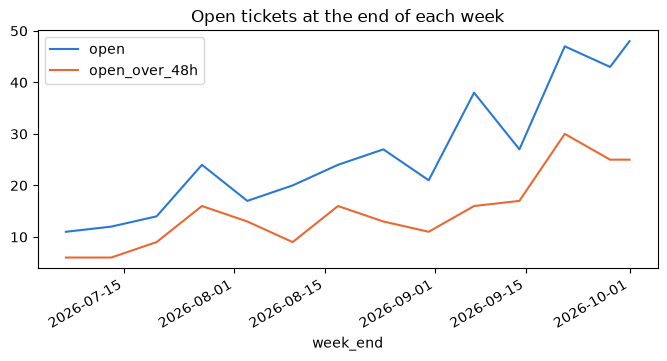

,week_end,open,open_over_48h
0,2026-07-06 00:00:00,11,6
1,2026-07-13 00:00:00,12,6
2,2026-07-20 00:00:00,14,9
3,2026-07-27 00:00:00,24,16
4,2026-08-03 00:00:00,17,13
5,2026-08-10 00:00:00,20,9
6,2026-08-17 00:00:00,24,16
7,2026-08-24 00:00:00,27,13
8,2026-08-31 00:00:00,21,11
9,2026-09-07 00:00:00,38,16


In [4]:
# For each Monday, count the tickets that were open at that moment
week_ends = list(pd.date_range("2026-07-06", "2026-09-28", freq="7D")) + [now]

rows = []
for day in week_ends:
    created_before = df["created_at"] < day
    not_closed_yet = df["final_closed_at"].isna() | (df["final_closed_at"] >= day)
    open_then = df[created_before & not_closed_yet]

    hours_open = (day - open_then["created_at"]).dt.total_seconds() / 3600
    older_than_48h = open_then[hours_open >= 48]

    rows.append({"week_end": day, "open": len(open_then), "open_over_48h": len(older_than_48h)})

backlog = pd.DataFrame(rows)

backlog.plot(x="week_end", y=["open", "open_over_48h"], color=["#2a78d6", "#eb6834"],
             title="Open tickets at the end of each week", figsize=(8, 3.5))
plt.show()
backlog

**What we see**

- Yes, open tickets grew: about 12 to 14 in mid-July, about 43 to 47 in late September.
- But new tickets also grew by 52% (390 in July, 592 in September).
- So part of the rise is simply more work coming in.

## Step 3: Which tickets take the most time?

We compare two groups: tickets solved by support alone, and tickets sent to engineering.

In [5]:
compare = df.groupby("escalated").agg(
    tickets=("ticket_id", "count"),
    typical_hours=("hours_to_close", "median"),
    average_rating=("csat_score", "mean"),
    total_waiting_hours=("age_hours", "sum"),
)

compare["share_of_tickets_%"] = compare["tickets"] / compare["tickets"].sum() * 100
compare["share_of_waiting_%"] = compare["total_waiting_hours"] / compare["total_waiting_hours"].sum() * 100
compare.index = ["Solved by support alone", "Sent to engineering"]
compare.round(1)

,tickets,typical_hours,average_rating,total_waiting_hours,share_of_tickets_%,share_of_waiting_%
Solved by support alone,958,12.6,4.0,19147.9,66.3,28.6
Sent to engineering,486,86.8,3.1,47855.5,33.7,71.4


**What we see**

- Tickets sent to engineering are only 34% of tickets, but 71% of all waiting time.
- They take about 87 hours. Tickets solved by support take about 13 hours.
- Clients rate them lower: 3.1 against 4.0.

So Meera is right that the slow tickets are the ones with engineering. Next: why are they slow?

## Step 4: What does engineering do with the tickets it gets?

The column `eng_outcome` tells us engineering's final answer.

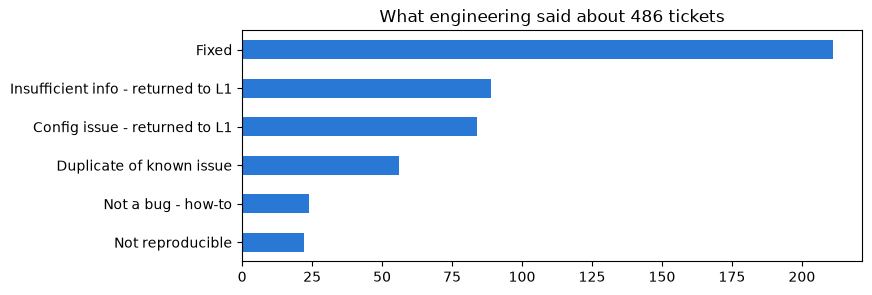

,tickets,typical_hours,average_rating
eng_outcome,,,
Fixed,211,64.8,3.4
Insufficient info - returned to L1,89,121.1,2.7
Config issue - returned to L1,84,128.6,2.4
Duplicate of known issue,56,67.5,3.5
Not a bug - how-to,24,68.7,3.2
Not reproducible,22,62.3,3.4


In [6]:
sent_to_eng = df[df["escalated"]]

outcomes = sent_to_eng.groupby("eng_outcome").agg(
    tickets=("ticket_id", "count"),
    typical_hours=("hours_to_close", "median"),
    average_rating=("csat_score", "mean"),
)
outcomes = outcomes.sort_values("tickets", ascending=False)

outcomes["tickets"].sort_values().plot(kind="barh", color="#2a78d6", figsize=(8, 3),
                                       title="What engineering said about 486 tickets")
plt.ylabel("")
plt.show()
outcomes.round(1)

In [7]:
fixed = sent_to_eng[sent_to_eng["eng_outcome"] == "Fixed"]
bounced = sent_to_eng[sent_to_eng["bounced"]]

print("Sent to engineering:", len(sent_to_eng))
print("Really fixed by engineering:", len(fixed))
print("Came back without a fix:", len(bounced))
print("Came back, as % of sent:", round(len(bounced) / len(sent_to_eng) * 100), "%")
print("Came back, as % of ALL tickets:", round(len(bounced) / len(df) * 100), "%")
print("Came back, as % of ALL waiting time:", round(bounced["age_hours"].sum() / df["age_hours"].sum() * 100), "%")

Sent to engineering: 486
Really fixed by engineering: 211
Came back without a fix: 275
Came back, as % of sent: 57 %
Came back, as % of ALL tickets: 19 %
Came back, as % of ALL waiting time: 47 %


**What we see**

- Engineering really fixed only 211 of 486 tickets.
- The other 275 (57%) came back without a fix. The reasons:
  - not enough information (89)
  - a settings problem that support could have fixed (84)
  - engineering already knew about it (56)
  - the client only needed to be shown how (24)
  - engineering could not see the problem (22)
- These 275 tickets are 19% of all tickets but 47% of all waiting time.

So Sandeep is right too. But look at the "Fixed" row: even a real fix takes about 65 hours, so
engineering is also slow.

## Step 5: What does each trip to engineering cost?

`eng_handoffs` is how many times a ticket went to engineering.

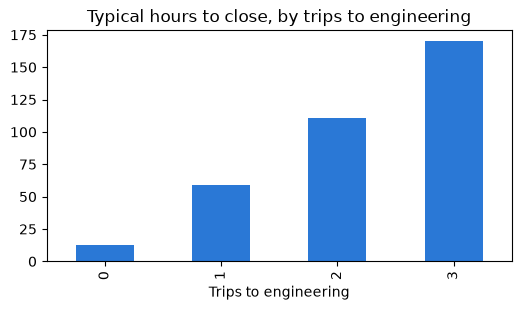

Tickets with 2 or more trips: 229


,tickets,typical_hours,average_rating
eng_handoffs,,,
0,958,12.6,4.0
1,257,58.6,3.6
2,167,110.4,2.8
3,62,169.9,2.1


In [8]:
trips = df.groupby("eng_handoffs").agg(
    tickets=("ticket_id", "count"),
    typical_hours=("hours_to_close", "median"),
    average_rating=("csat_score", "mean"),
)

trips["typical_hours"].plot(kind="bar", color="#2a78d6", figsize=(6, 3),
                            title="Typical hours to close, by trips to engineering")
plt.xlabel("Trips to engineering")
plt.show()

print("Tickets with 2 or more trips:", (df["eng_handoffs"] >= 2).sum())
trips.round(1)

**What we see**

- 1 trip: about 59 hours. 2 trips: about 110 hours. 3 trips: about 170 hours.
- Every extra trip adds about two days.
- The rating drops each time: 3.6, then 2.8, then 2.1.
- 229 tickets went to engineering two or more times.

This back-and-forth is the most expensive thing in the data.

## Step 6: Is it one type of problem?

In [9]:
by_category = df.groupby("category").agg(
    tickets=("ticket_id", "count"),
    sent_to_eng_rate=("escalated", "mean"),
    typical_hours=("hours_to_close", "median"),
)
# Of the tickets sent to engineering, what share came back?
by_category["came_back_rate"] = sent_to_eng.groupby("category")["bounced"].mean()

by_category.sort_values("tickets", ascending=False).round(2)

,tickets,sent_to_eng_rate,typical_hours,came_back_rate
category,,,,
Roster / booking not syncing,344,0.51,44.48,0.55
Live tracking / GPS incorrect,228,0.56,42.73,0.53
Report export failing,206,0.37,23.87,0.66
Cab delay / no-show complaint,147,0.10,10.75,0.36
How-to / feature request,104,0.12,8.98,0.75
Login / access issue,100,0.08,7.62,0.62
OTP / boarding issue,95,0.36,18.50,0.62
Billing / invoice discrepancy,88,0.30,39.62,0.50
Employee address / geocode change,75,0.15,17.93,0.55


**What we see**

- "Roster / booking not syncing" and "Live tracking / GPS incorrect" are the two biggest groups.
  Together they are 40% of all tickets, and more than half of them go to engineering.
- But tickets come back a lot in every category.

So this is not one bad category. It is a problem in the way tickets are handed over.

## Step 7: Is it some agents?

In [10]:
by_agent = df.groupby("assigned_agent").agg(
    tickets=("ticket_id", "count"),
    sent_to_eng_rate=("escalated", "mean"),
    typical_hours=("hours_to_close", "median"),
    reopened_rate=("reopened", "mean"),
    average_rating=("csat_score", "mean"),
)
by_agent["came_back_rate"] = sent_to_eng.groupby("assigned_agent")["bounced"].mean()

by_agent.round(2)

,tickets,sent_to_eng_rate,typical_hours,reopened_rate,average_rating,came_back_rate
assigned_agent,,,,,,
Ananya R,189,0.40,24.06,0.07,3.84,0.47
Arjun K,178,0.33,20.78,0.08,3.85,0.57
Karan B,217,0.16,11.88,0.29,3.13,0.63
Neha P,171,0.29,19.73,0.08,3.94,0.61
Priya D,186,0.33,22.38,0.09,3.78,0.54
Rahul T,151,0.62,44.48,0.08,3.52,0.75
Sneha M,176,0.35,25.78,0.05,3.72,0.49
Vikram S,176,0.30,20.83,0.05,3.92,0.40


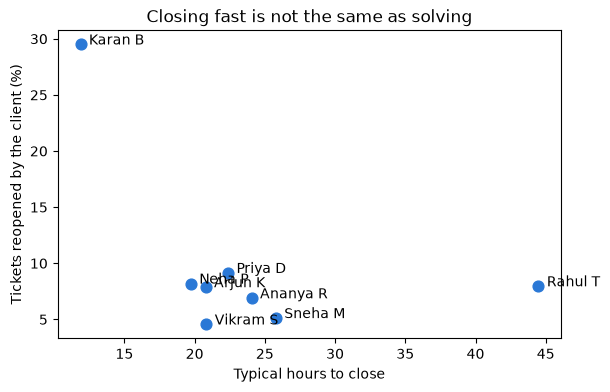

In [11]:
# Fast closing compared with how often the client reopens the ticket
plt.figure(figsize=(6.5, 4))
plt.scatter(by_agent["typical_hours"], by_agent["reopened_rate"] * 100, color="#2a78d6", s=60)
for name in by_agent.index:
    plt.text(by_agent.loc[name, "typical_hours"] + 0.6, by_agent.loc[name, "reopened_rate"] * 100, name)
plt.xlabel("Typical hours to close")
plt.ylabel("Tickets reopened by the client (%)")
plt.title("Closing fast is not the same as solving")
plt.show()

**What we see**

Two agents are different from the rest:

- **Rahul T** sends 62% of his tickets to engineering (others send 16% to 40%), and 75% of them
  come back. He sends too many.
- **Karan B** closes tickets fastest (about 12 hours) and sends the fewest to engineering. But
  clients reopen about 30% of his tickets (others: 5% to 9%), and his rating is the lowest. He
  closes tickets before they are really solved.

Meera said "some agents close tickets in a few hours, so it can be done fast". The data shows the
fastest agent is fast because the work comes back. **So "close faster" is the wrong goal.**

## Step 8: Things that do NOT matter

We check client size, channel and priority.

In [12]:
for col in ["client_tier", "channel", "priority"]:
    table = df.groupby(col).agg(tickets=("ticket_id", "count"), sent_to_eng_rate=("escalated", "mean"))
    print(table.round(2))
    print()

             tickets  sent_to_eng_rate
client_tier                           
Enterprise       614              0.34
Mid-market       656              0.34
SMB              174              0.33

               tickets  sent_to_eng_rate
channel                                 
Client portal      377              0.34
Email              553              0.34
Phone              292              0.33
WhatsApp           222              0.32

          tickets  sent_to_eng_rate
priority                           
P1             67              0.33
P2            264              0.35
P3            742              0.33
P4            371              0.34



**What we see**

About one third of tickets go to engineering in every group. Client size, channel and priority do
not explain the problem.

## Summary

| Who said what | Is it true? | Why |
|---|---|---|
| Open tickets are going up | Yes | From about 13 to about 45 at the end of a week |
| Engineering is slow (Meera) | Partly | Engineering tickets are 71% of waiting time, and a real fix takes about 65 hours |
| Support sends the wrong tickets (Sandeep) | Yes | 57% of tickets sent to engineering come back without a fix |
| Fast agents show it can be done fast (Meera) | No | The fastest agent has the most reopened tickets |

**The main problem:** tickets are sent to engineering that engineering cannot act on. They are 19% of
tickets and 47% of waiting time. We know the reasons, and fixing them needs no new staff.